# 80장 · Codex와 첫 투두 앱 만들기

학생이 ‘복습’이라는 할 일을 두 번 입력했습니다. 제목이 같아도 두 항목은 각각 완료하거나 삭제할 수 있어야 합니다. Codex에 건넬 요구를 이 행동으로 좁힌 뒤 제안 코드와 실행 결과를 검토합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.

## 코드 변경을 요청하기 전에 수용 조건 쓰기

Codex 요청 예시입니다. ‘단일 사용자용 투두 화면에서 제목 양끝의 공백을 제거하고 새 항목을 추가해 줘. 빈 제목은 거절하고 ID는 저장소가 발급해. 같은 제목 두 건을 각각 완료할 수 있어야 해. 변경할 함수와 확인할 사례를 먼저 설명해 줘.’ 아래 코드는 이 요청의 수용 조건을 검토할 수 있도록 마련한 수업용 예시입니다. Codex가 실제로 돌려준 코드는 직접 실행한 세션에서 확인하세요.


### 셀 01 · 항목을 추가해 레코드 확인하기

수업 커널의 Node.js로 실제 JavaScript를 실행합니다. 새 레코드의 시작 상태를 보세요.

In [1]:
import subprocess
def run_js(source):
    run = subprocess.run(["node", "--input-type=module", "-e", source],
                         text=True, capture_output=True, check=True, timeout=10)
    print(run.stdout.rstrip())
store_source = """
let nextId = 1;
const items = [];
function add(raw) {
  if (typeof raw !== "string" || raw.trim() === "") throw Error("INVALID_TITLE");
  const item = {id: nextId++, title: raw.trim(), completed: false};
  items.push(item);
  return item;
}
"""
run_js(store_source + 'console.log(JSON.stringify(add("  복습  ")));')

{"id":1,"title":"복습","completed":false}


id는 1, 제목은 복습, 완료 여부는 false입니다. 양끝 공백을 지워도 제목 안쪽 공백은 유지한다는 조건을 다음 입력에서도 확인하세요.

### 셀 02 · 빈 입력을 거절한 위치 확인

공백만 보낸 경우 저장소 길이도 함께 확인합니다.

run_js는 부를 때마다 새 Node 프로세스에서 시작합니다. 이 셀의 배열은 셀 01에서 추가한 항목을 기억하지 않습니다. 같은 행에 연속으로 한 조작을 확인하려면 그 조작을 한 번의 run_js 안에 넣으세요.

In [2]:
run_js(store_source + '''
try { add("   "); }
catch (error) { console.log(error.message + " " + items.length); }
''')

INVALID_TITLE 0


INVALID_TITLE 0입니다. 저장 전에 검사해서 빈 항목과 불필요한 ID가 생기지 않았습니다.

## diff의 변경이 수용 조건을 지키는지 보기

제안에 items.find(row => row.title === title)가 들어갔다고 가정하세요. 제목이 같은 두 항목 중 첫 번째만 찾으므로 사용자가 누른 두 번째 행도 구별할 ID를 받아야 합니다.

<!-- motion:blank-title -->
**빈 제목을 거절하면 목록에는 몇 건이 남을까요?**

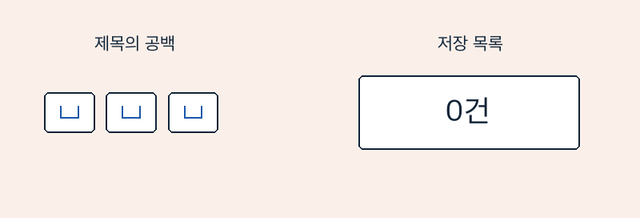

공백뿐인 제목을 정리하면 쓸 글자가 없습니다. INVALID_TITLE을 돌려주고 저장 목록에는 새 행을 만들지 않습니다.
<!-- /motion -->


### 과제 03 · 선택한 ID의 항목만 완료하기

같은 제목 두 건을 추가한 뒤 id 2만 완료하도록 JavaScript 한 줄을 작성하세요.

In [3]:
# run_js에 store_source와 변경 코드를 함께 전달하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>run_js(store_source + &#x27;&#x27;&#x27;
add(&quot;복습&quot;); add(&quot;복습&quot;);
items.find(row =&gt; row.id === 2).completed = true;
console.log(JSON.stringify(items.map(row =&gt; [row.id, row.completed])));
&#x27;&#x27;&#x27;)</code></pre>
<p>실행 결과</p><pre><code>[[1,false],[2,true]]</code></pre>
<p>첫 항목은 false, 두 번째는 true입니다. Codex에 수정 요청을 할 때는 중복 제목 두 개, 누른 ID, 기대한 완료 상태와 실제 결과를 함께 제시하세요.</p>
</details>

## 돌아보기

현재 저장소는 JavaScript 프로세스 안의 배열입니다. 새 실행에서 사라지는지 확인하고 81장에서 서버로 옮길 때 그대로 유지할 필드 id·title·completed를 짚어 보세요.